# 04 - Generalized coupled mode equations

This notebook extends the pump-signal-idler CMEs of notebook 03 with more modes and with the reflections at the device ends and at the connectors to the external lines.

## Overview

Besides 3WM amplification, a real device shows:

* **pump harmonics** at $2 f_p$, $3 f_p$, ...;
* **frequency conversion**, such as $f_p + f_s$ and $f_p + f_i$;
* **signal and idler harmonics**;
* **imperfections**: loss along the line and reflections at its ends.

`twpasolver` describes the modes with a `ModeSet` and solves the CMEs with two models, `simple` and `bloch`.

## Setup

We load the KI-TWPA of notebook 03 and plot its response, with the pump at 16.2 GHz. The higher-order processes involve frequencies well above the pump, so the grid extends to its harmonics.

In [ ]:
import importlib
import twpasolver

importlib.reload(twpasolver)

(-20.0, 1.0)

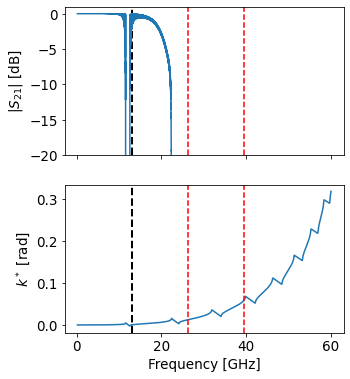

In [68]:
import logging

import matplotlib.pyplot as plt
import numpy as np

from twpasolver import ModeSet, Ports, TWPAnalysis
from twpasolver.cmes.solver_config import BlochSolverConfig
from twpasolver.logger import log
from twpasolver.models import Inductance

log.setLevel(logging.WARNING)

plt.rcParams["font.size"] = 13.5
plt.rcParams["axes.axisbelow"] = True

twpa_file = "TWPA_highpassloss.json"  # Representative circuit model from https://doi.org/10.1103/yg71-j2dn
a = TWPAnalysis(twpa=twpa_file, freqs=(0.2, 60, 2e-3), unit="GHz")

pump = 13.15
ax = a.plot_response(pump_freq=pump)
for i in range(2):
    ax[i].axvline(2 * pump, ls="--", c="r")
    ax[i].axvline(3 * pump, ls="--", c="r")
ax[0].set_ylim(-20, 1)

### The grid reaches 60 GHz to include the 2nd and 3rd pump harmonics (red dashed lines). The line is dispersive, so each harmonic has its own wavenumber and takes part in further mixing processes.

## Mode sets

A `ModeSet` holds any number of modes connected by frequency relations:

* **independent modes**: the modes not defined by a relation are the input tones (here pump `p` and signal `s`); all other modes follow from them;
* **frequencies**: every mode frequency is an integer combination of the independent tones, applied to whole frequency arrays;
* **RWA terms**: the 3WM and 4WM terms that survive the rotating-wave approximation (RWA) are found exactly from the relations and build the CMEs.

When a gain is computed, the wavenumber, loss and impedance of each mode are interpolated from the linear response at its frequency.

A custom set with the idler and the 2nd pump harmonic:

p = p (independent)
s = s (independent)
i = p - s
p2 = 2*p


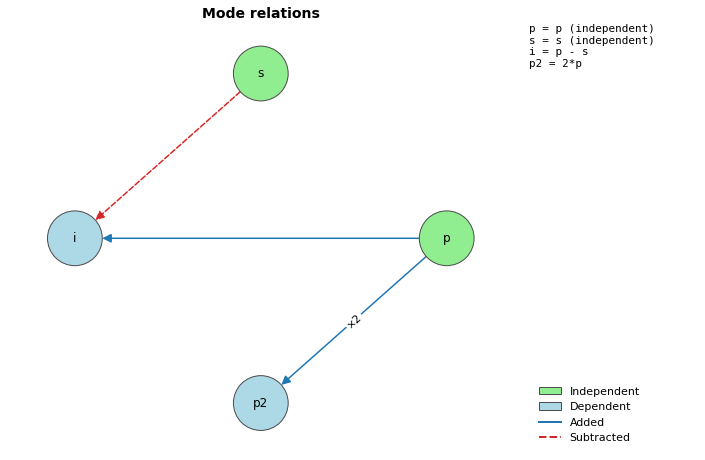

In [69]:
modes_p2 = ModeSet(["p", "s", "i", "p2"], [["i", "p-s"], ["p2", "p+p"]])
print(modes_p2)
_ = modes_p2.plot_relations(layout="circular")

The graph shows the relations: green nodes are independent modes (`p`, `s`), blue nodes dependent ones (`i`, `p2`); blue arrows are positive and red dashed arrows negative frequency contributions.

`rwa_terms(power)` lists the RWA terms with `power` mode factors (2 for 3WM, 3 for 4WM). Each tuple is `(driven mode index, factor indices, driven mode, factors, coefficient)`; factor indices at or above the number of modes, printed with a minus sign, are complex conjugates, and the coefficient $1/\prod n_r!$ accounts for repeated factors. The 3WM terms here come from $\omega_s+\omega_i=\omega_p$ and $\omega_p+\omega_p=\omega_{p2}$:

In [70]:
for term in modes_p2.rwa_terms(2):
    print(term)

(0, (1, 2), 'p', ['s', 'i'], 1.0)
(0, (3, 4), 'p', ['p2', '-p'], 1.0)
(1, (0, 6), 's', ['p', '-i'], 1.0)
(2, (0, 5), 'i', ['p', '-s'], 1.0)
(3, (0, 0), 'p2', ['p', 'p'], 0.5)


Realistic simulations include the pump harmonics and the frequency-conversion products of signal and idler, which are linear in the signal and shape the small-signal gain; `ModeSet.extended_3wm` builds such a set:

p = p (independent)
s = s (independent)
i = p - s
ps = p + s
pi = 2*p - s
p2s = 2*p + s
p2i = 3*p - s
p2 = 2*p
p3 = 3*p
41 3WM terms, 230 4WM terms


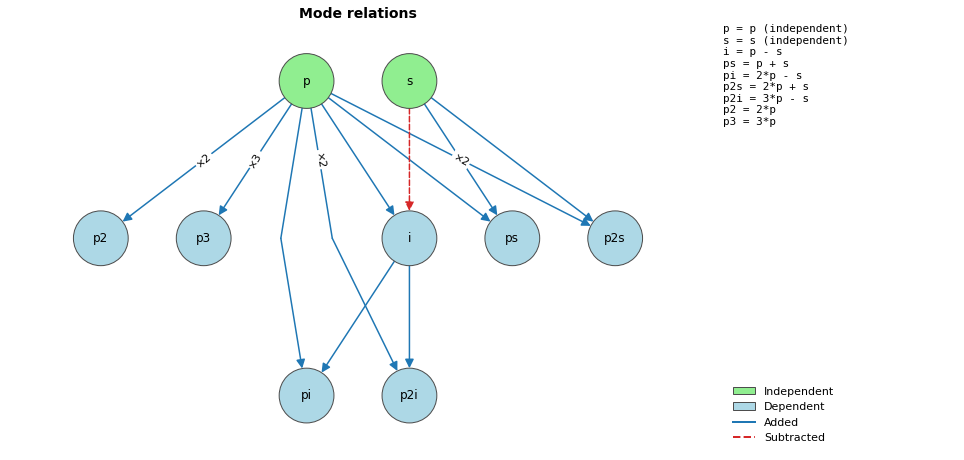

In [71]:
modes_ext = ModeSet.extended_3wm(n_pump_harmonics=2, n_frequency_conversion=2)
print(modes_ext)
print(
    f"{len(modes_ext.rwa_terms(2))} 3WM terms, {len(modes_ext.rwa_terms(3))} 4WM terms"
)
_ = modes_ext.plot_relations()

This set contains:

* **pump harmonics**: `p`, `p2`, `p3`;
* **3WM amplification**: `s`, `i`;
* **frequency conversion**: `ps` ($f_p+f_s$), `pi` ($f_p+f_i$), `p2s` ($2f_p+f_s$) and `p2i` ($2f_p+f_i$).

The hierarchical layout puts the independent modes on top. The number of RWA terms, and with it the cost of a solve, grows quickly with the number of modes.

### Sidebands

Products of two or more signal photons, such as the harmonic $2f_s$ and its 3WM idler $f_p - 2f_s$, are second or higher order in the signal: they leave the small-signal gain unchanged and matter in compression. `extended_3wm` builds them like the signal chain: for every order $m \geq 2$ up to `n_signal_harmonics + 1`, the harmonic `s{m}` ($m f_s$) and its idler `i{m}` ($f_p - m f_s$), then their conversion products $n f_p + m f_s$ and $(n+1) f_p - m f_s$ up to the pump order `n_sideband_conversion`. The idler $f_p - m f_s$ crosses 0 Hz at $f_s = f_p/m$, so the signals must stay on one side of it.

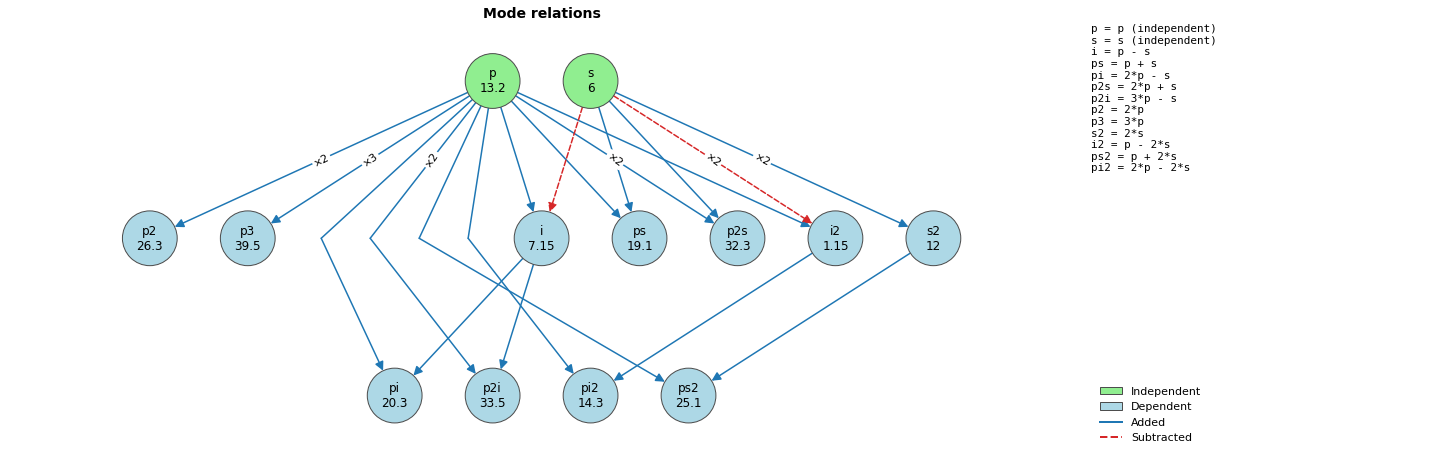

In [72]:
modes_sb = ModeSet.extended_3wm(
    n_pump_harmonics=2,
    n_frequency_conversion=2,
    n_signal_harmonics=1,
    n_sideband_conversion=1,
)
_ = modes_sb.plot_relations(tones={"p": pump, "s": 6.0})

## Gain models

The `model` argument of `gain` selects the CME solver:

* **`simple`** (default): the textbook CMEs of a homogeneous line, forward waves only. The periodic loading enters only through the Bloch wavenumber, and the couplings are those of a uniform medium, so they are approximate for loaded lines, especially near stopbands. Reflections and connectors are ignored. It is fast.
* **`bloch`**: forward and backward waves in the exact Bloch-mode basis of the supercell, with couplings from the current profile inside the supercell and exact boundary conditions at the ports. The two directions are iterated to self-consistency (configured by `BlochSolverConfig`), and modes close to a stopband edge are treated on a fixed basis. It is more accurate and more expensive.

Both take the same `modes`. We first compare the basic 3WM set with the extended one using the fast `simple` model:

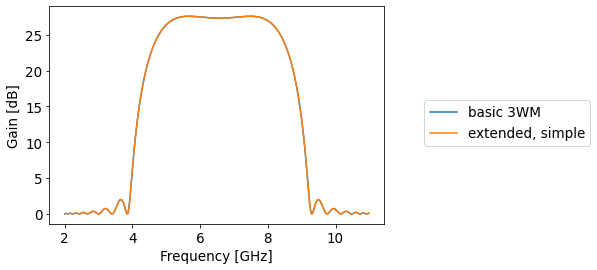

In [73]:
s_arange = np.arange(2, 11, 0.01)

res_base = a.gain(signal_freqs=s_arange, Is0=1e-7, pump=pump)
res_extended = a.gain(
    signal_freqs=s_arange,
    Is0=1e-7,
    pump=pump,
    model="simple",
)

ax = res_base.plot()
ax.plot(s_arange, res_extended.gain_db)
ax.legend(["basic 3WM", "extended, simple"], bbox_to_anchor=(1.1, 0.6))

The extra modes exchange power with pump, signal and idler and reshape the gain profile. Once compiled, the `simple` solver stays fast even with many more modes.

## Reflections: the `bloch` model

`BlochSolverConfig` configures the `bloch` model:

* `passes`: maximum number of forward-backward passes;
* `convergence_threshold`: relative residual below which the iteration stops;
* `anderson_depth`: number of previous passes used to accelerate the iteration; raise it with `passes` (for example to `passes - 10`);
* `kappa_cutoff`: phase-mismatch cutoff that drops negligible 3WM and 4WM terms, which can greatly reduce the cost;
* `m_max`: largest reciprocal lattice vector of the supercell kept for quasi-phase-matched terms;
* `edge_threshold`, `simulate_stopband_modes`: treatment of the modes inside or close to a stopband, solved on a fixed basis of Bloch vectors (see [Models and Physics Notes](../physics.rst));
* `save_all_passes`: keep every pass, to inspect the convergence.

Both models integrate the CMEs with an adaptive RK45 solver set by `RKSolverConfig` (`atol`, `rtol`, `first_step`, `max_steps_per_cell`), passed to `gain` as `rk_config`.

A `GainResult` has the same fields for both models, and the `bloch` model fills more of them: besides `gain_db` ($S_{21}$) it gives the reflection `gain_db_11` ($S_{11}$), the backward currents `I_bwd` and the solver tables in `diagnostics`.

############WE ENTER EHERE##########
PORT OUT IS 1
############WE ENTER EHERE##########
PORT OUT IS 1
converged at 900 of 900 signal frequencies


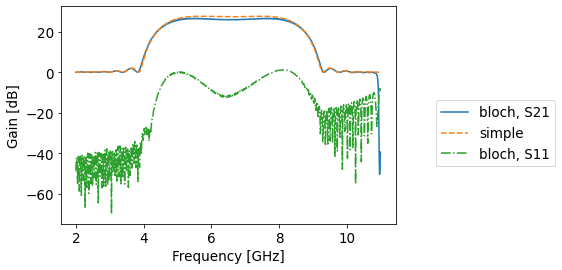

In [74]:
bloch_config = BlochSolverConfig(
    passes=40,
    anderson_depth=30,
    kappa_cutoff=0.25,
    convergence_threshold=1e-2,
    save_all_passes=False,
)

res_bloch = a.gain(
    signal_freqs=s_arange,
    Is0=1e-7,
    pump=pump,
    model="bloch",
    modes=modes_ext,
    bloch_config=bloch_config,
)
print(f"converged at {res_bloch.converged.sum()} of {len(s_arange)} signal frequencies")

ax = res_bloch.plot()
ax.plot(s_arange, res_extended.gain_db, ls="--")
ax.plot(s_arange, res_bloch.gain_db_11, ls="-.")
ax.legend(["bloch, S21", "simple", "bloch, S11"], bbox_to_anchor=(1.1, 0.6))

The `bloch` gain shows ripples from the reflections, which the `simple` model cannot capture, and its exact couplings also shift the gain level. Use it for quantitative comparison with experiment, at a cost typically tens of times higher than `simple`, depending on `passes` and `kappa_cutoff`.

### Port currents and S-parameters

The gains are ratios of the currents in the external lines at the two ends of the device, stored with shape `(n_freq, n_modes)`:

* `a_in`, `a_out`: currents incident on the device at $x=0$ and at $x=L$;
* `b_in`, `b_out`: currents leaving the device at $x=0$ and at $x=L$.

For the signal, $S_{21}=b_\mathrm{out}/a_\mathrm{in}$, $S_{11}=b_\mathrm{in}/a_\mathrm{in}$, $S_{12}=b_\mathrm{in}/a_\mathrm{out}$ and $S_{22}=b_\mathrm{out}/a_\mathrm{out}$ (`gain_db`, `gain_db_11`, `gain_db_12`, `gain_db_22`, in dB). Only $x=0$ is driven here, so $a_\mathrm{out}=0$ and $S_{12}$, $S_{22}$ are NaN; `initial_amplitudes_bwd` drives the device from $x=L$. `r.mode(label)` gives the index of a mode:

In [75]:
s = res_bloch.mode("s")
S11 = 20 * np.log10(np.abs(res_bloch.b_in[:, s] / res_bloch.a_in[:, s]))
print("a_in shape:", res_bloch.a_in.shape, " modes:", list(res_bloch.mode_labels))
print(
    "S11 from port currents matches gain_db_11:", np.allclose(S11, res_bloch.gain_db_11)
)
print(
    "S12, S22 all NaN:",
    np.isnan(res_bloch.gain_db_12).all(),
    np.isnan(res_bloch.gain_db_22).all(),
)
p2 = res_bloch.mode("p2")
print(
    f"max |b_out| of p2: {np.abs(res_bloch.b_out[:, p2]).max():.2e} A, max |b_in| of p2: {np.abs(res_bloch.b_in[:, p2]).max():.2e} A"
)

a_in shape: (900, 9)  modes: ['p', 's', 'i', 'ps', 'pi', 'p2s', 'p2i', 'p2', 'p3']
S11 from port currents matches gain_db_11: True
S12, S22 all NaN: True True
max |b_out| of p2: 4.13e-06 A, max |b_in| of p2: 3.45e-07 A


In [76]:
p3 = res_bloch.mode("p3") 
test = res_bloch.b_out

Every mode has outgoing currents, so `b_in` and `b_out` also show how much of each generated mode (here the 2nd pump harmonic) leaves the device at either end.

## Mode currents along the line

`r.plot_currents()` plots the current of each mode, averaged over the signal frequencies, along the line (in unit cells). It shows which processes matter and how power flows between modes:

(-150.0, -25.0)

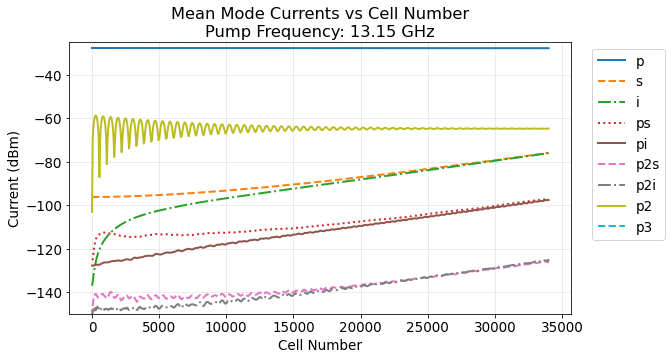

In [77]:
_ = res_bloch.plot_currents()
plt.ylim([-150, -25])

The `bloch` model also gives the backward wave. `r.I_bwd` is stored on the same position grid `r.x` as `r.I_fwd` ($x=0$ at the input), so `r.I_bwd[..., 0]` is the backward wave arriving at the input and `r.I_bwd[..., -1]` the one launched at the output:

x: (680,)  I_fwd: (900, 9, 680)  I_bwd: (900, 9, 680)


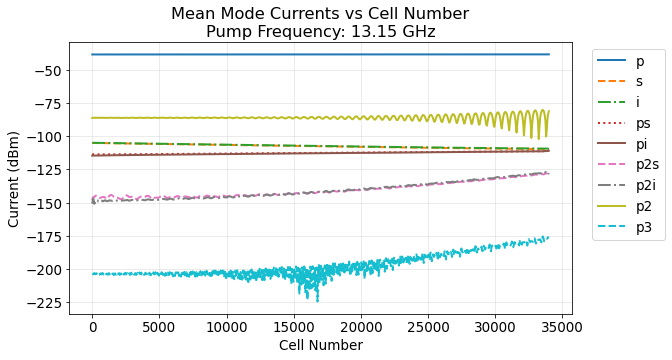

In [78]:
print(
    "x:",
    res_bloch.x.shape,
    " I_fwd:",
    res_bloch.I_fwd.shape,
    " I_bwd:",
    res_bloch.I_bwd.shape,
)
_ = res_bloch.plot_currents(backward=True)

The backward modes take part in different processes and evolve differently from the forward ones. The plots show:

* **pump depletion**: the pump current decreases as power goes to the other modes, or is dissipated in a lossy line;
* **signal amplification**: the signal grows in the gain region;
* **idler generation**: the idler grows with the signal;
* **harmonics**: the weight of the higher-order modes;
* **backward wave**: nonzero because of reflections at the ports and along the line; it feeds back into the forward wave and causes the gain ripples above.

Modes that stay negligible along the whole line can usually be dropped from the set.

### Zooming in on the ripples

We zoom in on a narrow range where the reflections shape the gain most, saving every forward-backward pass:

############WE ENTER EHERE##########
PORT OUT IS 1
############WE ENTER EHERE##########
PORT OUT IS 1


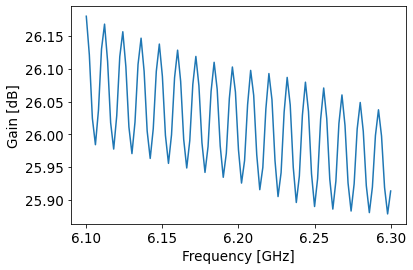

In [79]:
bloch_config.save_all_passes = True
s_arange_narrow = np.arange(6.1, 6.3, 0.002)
res_narrow = a.gain(
    signal_freqs=s_arange_narrow,
    Is0=1e-7,
    pump=pump,
    model="bloch",
    modes=modes_ext,
    bloch_config=bloch_config,
)
ax = res_narrow.plot()

### Forward-backward convergence

With `save_all_passes=True`, `r.history` holds every pass on a leading pass axis of length `passes` (`r.history["gain_db"][p]` is $S_{21}$ after pass `p`). A point that converges earlier is NaN after its last pass, and `r.diagnostics["passes_used"]` gives the passes each point ran.

40 passes stored, converged at 101 of 101 frequencies


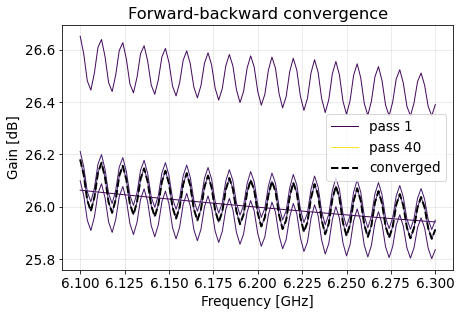

In [80]:
passes_gain_db = res_narrow.history["gain_db"]
n_passes = len(passes_gain_db)
print(
    f"{n_passes} passes stored, converged at {res_narrow.converged.sum()} of {len(s_arange_narrow)} frequencies"
)

fig, ax = plt.subplots(figsize=(7, 4.5))
for i, g in enumerate(passes_gain_db):
    ax.plot(
        s_arange_narrow,
        g,
        color=plt.cm.viridis(i / max(1, n_passes - 1)),
        lw=1,
        label=f"pass {i + 1}" if i in (0, n_passes - 1) else None,
    )
ax.plot(
    s_arange_narrow, res_narrow.gain_db, color="k", lw=2, ls="--", label="converged"
)
ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Gain [dB]")
ax.set_title("Forward-backward convergence")
ax.legend()
ax.grid(alpha=0.3)

The first pass already gives the smooth gain; the following ones add the ripples of the backward wave. `convergence_threshold` sets when the iteration stops, and `r.converged` flags the points that reached it within `passes`.

### Connectors

TWPAs are very sensitive to reflections, so reproducing the ripple amplitude requires modeling what the device is connected to. Connectors are `TwoPortModel`s passed as `ports=Ports(input=..., output=...)`: port 1 of a connector faces the external line (impedance `Ports.Z_ext`, 50 $\Omega$ by default) and port 2 the TWPA, and `input` is used at both ends when `output` is not set. Only the `bloch` model includes connectors. Here a small series inductance models the wirebonds between the sample and the external lines.

############WE ENTER EHERE##########
PORT OUT IS 1
############WE ENTER EHERE##########
PORT OUT IS 1


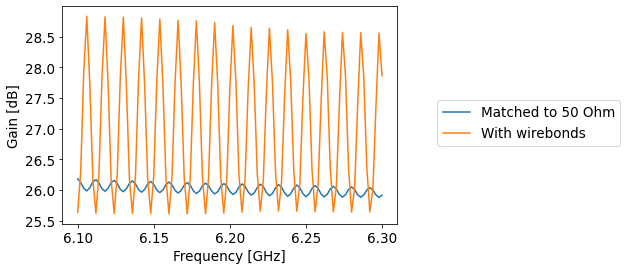

In [59]:
wirebonds = Inductance(L=1e-10)
a.ports = Ports(input=wirebonds)

bloch_config.save_all_passes = False
res_narrow_wb = a.gain(
    signal_freqs=s_arange_narrow,
    Is0=1e-7,
    pump=pump,
    model="bloch",
    modes=modes_ext,
    bloch_config=bloch_config,
)
ax = res_narrow.plot()
ax.plot(s_arange_narrow, res_narrow_wb.gain_db)
ax.legend(["Matched to 50 Ohm", "With wirebonds"], bbox_to_anchor=(1.1, 0.6))

The wirebond inductance adds a reactive mismatch at both ends: the ripples grow from about 1 dB to 6-7 dB peak to peak around the same mean gain, which is why the connectors must be modeled to compare ripple amplitudes with measurements.

Notebook 05 builds two other designs: a resonantly phase-matched 4WM line and a Floquet-mode TWPA made of segments.